In [2]:
import os
import pandas as pd

In [3]:
base_path = "/content/EDA_PSUPR_Project/COVID-19 Radiography Database"
meta_base = base_path


In [4]:
base_path = r"C:\Users\rosen\Documents\AIS\EDA_PSUPR_Project\COVID-19 Radiography Database"    #local path

#base_path = "/content/EDA_PSUPR_Project/COVID-19 Radiography Database"                          #with colab

folders = {"COVID": "COVID",
    "Viral Pneumonia": "Viral Pneumonia",
    "NORMAL": "NORMAL"}

for label, folder in folders.items():
    path = os.path.join(base_path, folder)

    count = len([
        f for f in os.listdir(path)
        if f.lower().endswith(".png")
    ])

    print(f"{label}: {count} images")

COVID: 1200 images
Viral Pneumonia: 1345 images
NORMAL: 1341 images


In [5]:
#building df
import os
import pandas as pd
from pathlib import Path

# Keep the source names exactly as they exist in the folders
folders = {
    "COVID": "COVID",
    "Pneumonia": "Viral Pneumonia",
    "Healthy": "NORMAL"
}

records = []

for label, folder in folders.items():
    folder_path = Path(base_path) / folder

    for filepath in folder_path.glob("*.png"):
        records.append({
            "filepath": str(filepath),
            "filename": filepath.name,
            "label": label,
            "source_dataset": "COVID_Radiography_Database"
        })

dataset1_df = pd.DataFrame(records)

print("Total images:", len(dataset1_df))
print("\nClass distribution:")
print(dataset1_df["label"].value_counts())

display(dataset1_df.head())

Total images: 3886

Class distribution:
label
Pneumonia    1345
Healthy      1341
COVID        1200
Name: count, dtype: int64


,filepath,filename,label,source_dataset
0,C:\Users\rosen\Documents\AIS\EDA_PSUPR_Project...,COVID (1).png,COVID,COVID_Radiography_Database
1,C:\Users\rosen\Documents\AIS\EDA_PSUPR_Project...,COVID (10).png,COVID,COVID_Radiography_Database
2,C:\Users\rosen\Documents\AIS\EDA_PSUPR_Project...,COVID (100).png,COVID,COVID_Radiography_Database
3,C:\Users\rosen\Documents\AIS\EDA_PSUPR_Project...,COVID (1000).png,COVID,COVID_Radiography_Database
4,C:\Users\rosen\Documents\AIS\EDA_PSUPR_Project...,COVID (1001).png,COVID,COVID_Radiography_Database


step 2: image validation and properties. look for unreadable/corrupted images, greyscale vs rgb, image dimestion and aspect ratios.
CNN needs a consistent input format.

In [6]:
from PIL import Image
import numpy as np

image_properties = []
invalid_images = []

for _, row in dataset1_df.iterrows():
    try:
        with Image.open(row["filepath"]) as img:
            img.verify()  # confirms the file is not corrupted

        # Reopen after verify() because verify closes the usable image object
        with Image.open(row["filepath"]) as img:
            width, height = img.size

            image_properties.append({
                "filepath": row["filepath"],
                "filename": row["filename"],
                "label": row["label"],
                "mode": img.mode,
                "width": width,
                "height": height,
                "aspect_ratio": round(width / height, 4)
            })

    except Exception as e:
        invalid_images.append({
            "filepath": row["filepath"],
            "error": str(e)
        })

properties_df = pd.DataFrame(image_properties)
invalid_df = pd.DataFrame(invalid_images)

print("Unreadable/corrupted images:", len(invalid_df))

print("\nImage modes by class:")
print(properties_df.groupby(["label", "mode"]).size())

print("\nDimension summary by class:")
display(
    properties_df.groupby("label")[["width", "height", "aspect_ratio"]]
    .describe()
)

Unreadable/corrupted images: 0

Image modes by class:
label      mode
COVID      L       1131
           RGB       69
Healthy    L       1341
Pneumonia  L       1205
           RGB      140
dtype: int64

Dimension summary by class:


width                                                           \
            count         mean         std     min     25%     50%     75%   
label                                                                        
COVID      1200.0   339.968333  194.356672   187.0   256.0   331.0   331.0   
Healthy    1341.0  1024.000000    0.000000  1024.0  1024.0  1024.0  1024.0   
Pneumonia  1345.0  1024.000000    0.000000  1024.0  1024.0  1024.0  1024.0   

                   height            ...                 aspect_ratio  \
              max   count      mean  ...     75%     max        count   
label                                ...                                
COVID      1275.0  1200.0   329.435  ...   331.0  1053.0       1200.0   
Healthy    1024.0  1341.0  1024.000  ...  1024.0  1024.0       1341.0   
Pneumonia  1024.0  1345.0  1024.000  ...  1024.0  1024.0       1345.0   

                                                              
               mean       std     min  25%  50%  75%     max  
label                                                         
COVID      1.011625  0.050076  0.8216  1.0  1.0  1.0  1.2843  
Healthy    1.000000  0.000000  1.0000  1.0  1.0  1.0  1.0000  
Pneumonia  1.000000  0.000000  1.0000  1.0  1.0  1.0  1.0000  

[3 rows x 24 columns]

In [7]:
#exact duplicate check
import hashlib

def get_file_hash(filepath, chunk_size=8192):
    hasher = hashlib.sha256()

    with open(filepath, "rb") as file:
        for chunk in iter(lambda: file.read(chunk_size), b""):
            hasher.update(chunk)

    return hasher.hexdigest()

dataset1_df["exact_hash"] = dataset1_df["filepath"].apply(get_file_hash)

exact_duplicates = (
    dataset1_df[dataset1_df.duplicated("exact_hash", keep=False)]
    .sort_values("exact_hash")
)

print("Images involved in exact duplicates:", len(exact_duplicates))
print("Unique duplicated-image groups:", exact_duplicates["exact_hash"].nunique())

display(
    exact_duplicates[
        ["label", "filename", "exact_hash"]
    ].head(20)
)

Images involved in exact duplicates: 12
Unique duplicated-image groups: 6


,label,filename,exact_hash
1390,Pneumonia,Viral Pneumonia (117).png,2f31e0d29bbf898d5e59f5901d5d116da0b3a4c8b71d2c...
1401,Pneumonia,Viral Pneumonia (118).png,2f31e0d29bbf898d5e59f5901d5d116da0b3a4c8b71d2c...
3615,Healthy,NORMAL (755).png,79e0dd4d8e77dfb92b8d6d931725c78d20a4254c370384...
3616,Healthy,NORMAL (756).png,79e0dd4d8e77dfb92b8d6d931725c78d20a4254c370384...
2096,Pneumonia,Viral Pneumonia (595).png,bf571cbe18de8151dfbeabcbcc81697968b73cbca2348c...
2097,Pneumonia,Viral Pneumonia (596).png,bf571cbe18de8151dfbeabcbcc81697968b73cbca2348c...
1260,Pneumonia,Viral Pneumonia (1052).png,c49481d35103a74163c124402e268770247d5cd8cda7e4...
1261,Pneumonia,Viral Pneumonia (1053).png,c49481d35103a74163c124402e268770247d5cd8cda7e4...
2494,Pneumonia,Viral Pneumonia (953).png,c6bdf02f097504b6147c0999efb1774b6deed3381d2167...
2495,Pneumonia,Viral Pneumonia (954).png,c6bdf02f097504b6147c0999efb1774b6deed3381d2167...


In [8]:
exact_duplicate_summary = (
    exact_duplicates
    .groupby("exact_hash")
    .agg(
        images_in_group=("filename", "count"),
        labels=("label", lambda x: sorted(x.unique())),
        files=("filename", list)
    )
    .reset_index()
)

exact_duplicate_summary["different_labels"] = (
    exact_duplicate_summary["labels"].apply(len) > 1
)

display(
    exact_duplicate_summary[
        ["images_in_group", "labels", "different_labels", "files"]
    ]
)

print(
    "Exact duplicate groups with conflicting labels:",
    exact_duplicate_summary["different_labels"].sum()
)

,images_in_group,labels,different_labels,files
0,2,[Pneumonia],False,"[Viral Pneumonia (117).png, Viral Pneumonia (1..."
1,2,[Healthy],False,"[NORMAL (755).png, NORMAL (756).png]"
2,2,[Pneumonia],False,"[Viral Pneumonia (595).png, Viral Pneumonia (5..."
3,2,[Pneumonia],False,"[Viral Pneumonia (1052).png, Viral Pneumonia (..."
4,2,[Pneumonia],False,"[Viral Pneumonia (953).png, Viral Pneumonia (9..."
5,2,[Pneumonia],False,"[Viral Pneumonia (74).png, Viral Pneumonia (75..."


Exact duplicate groups with conflicting labels: 0


there is no contracdictory label so it's good. we can safely remove one of the each duplicate sets

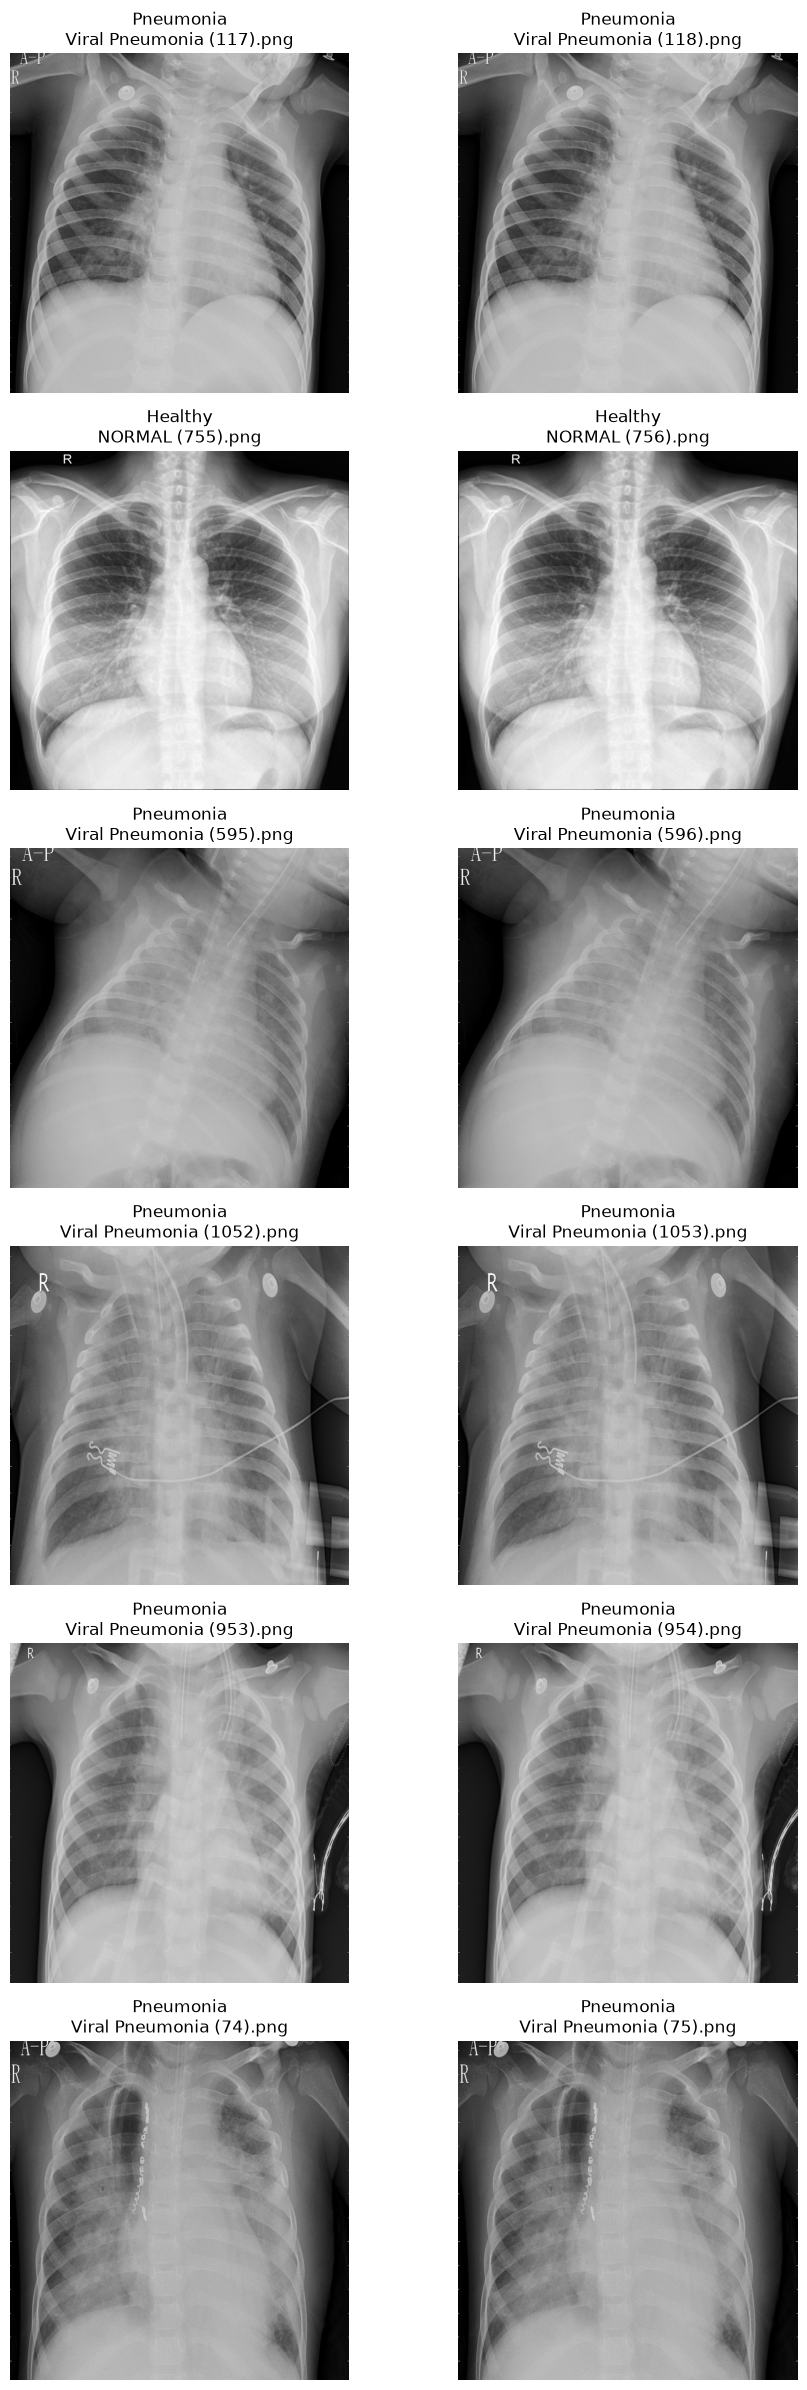

In [9]:
import matplotlib.pyplot as plt
from PIL import Image

n_groups = len(exact_duplicate_summary)

fig, axes = plt.subplots(n_groups, 2, figsize=(10, 4 * n_groups))

for row_idx, (_, group) in enumerate(exact_duplicate_summary.iterrows()):
    filenames = group["files"]

    pair_df = dataset1_df[
        dataset1_df["filename"].isin(filenames)
    ].sort_values("filepath")

    for col_idx, (_, image_row) in enumerate(pair_df.iterrows()):
        with Image.open(image_row["filepath"]) as img:
            axes[row_idx, col_idx].imshow(img, cmap="gray")

        axes[row_idx, col_idx].set_title(
            f'{image_row["label"]}\n{image_row["filename"]}'
        )
        axes[row_idx, col_idx].axis("off")

plt.tight_layout()
plt.show()

In [10]:
# Keep one deterministic representative from each exact-duplicate group
dataset1_clean_df = (
    dataset1_df
    .sort_values(["exact_hash", "filepath"])
    .drop_duplicates(subset="exact_hash", keep="first")
    .reset_index(drop=True)
)

dataset1_removed_exact_df = (
    dataset1_df
    .sort_values(["exact_hash", "filepath"])
    .loc[lambda df: df.duplicated(subset="exact_hash", keep="first")]
    .reset_index(drop=True)
)

print("Original images:", len(dataset1_df))
print("Removed exact duplicate copies:", len(dataset1_removed_exact_df))
print("Usable images after exact deduplication:", len(dataset1_clean_df))

print("\nRemaining class distribution:")
print(dataset1_clean_df["label"].value_counts())

Original images: 3886
Removed exact duplicate copies: 6
Usable images after exact deduplication: 3880

Remaining class distribution:
label
Pneumonia    1340
Healthy      1340
COVID        1200
Name: count, dtype: int64


In [11]:
%pip install -q ImageHash

Note: you may need to restart the kernel to use updated packages.


In [12]:
#find near duplicates using perceptual hashing
import imagehash
from PIL import Image
from itertools import combinations

# Create a perceptual hash for each remaining image
dataset1_clean_df["phash"] = dataset1_clean_df["filepath"].apply(
    lambda path: str(imagehash.phash(Image.open(path), hash_size=8))
)

# Convert hexadecimal hash strings to integers for fast Hamming-distance comparison
phash_values = dataset1_clean_df["phash"].apply(lambda x: int(x, 16)).to_list()

near_duplicate_pairs = []

for i, j in combinations(range(len(dataset1_clean_df)), 2):
    distance = (phash_values[i] ^ phash_values[j]).bit_count()

    # 0–2 is a strict screening range: likely same / very closely modified image
    if distance <= 2:
        near_duplicate_pairs.append({
            "index_1": i,
            "index_2": j,
            "label_1": dataset1_clean_df.iloc[i]["label"],
            "filename_1": dataset1_clean_df.iloc[i]["filename"],
            "label_2": dataset1_clean_df.iloc[j]["label"],
            "filename_2": dataset1_clean_df.iloc[j]["filename"],
            "phash_distance": distance
        })

near_duplicate_df = pd.DataFrame(near_duplicate_pairs)

print("Potential near-duplicate pairs (pHash distance ≤ 2):", len(near_duplicate_df))

print("\nPairs by label combination:")
display(
    near_duplicate_df
    .groupby(["label_1", "label_2"])
    .size()
    .reset_index(name="pair_count")
    .sort_values("pair_count", ascending=False)
)

print("\nDistance distribution:")
print(near_duplicate_df["phash_distance"].value_counts().sort_index())

Potential near-duplicate pairs (pHash distance ≤ 2): 283

Pairs by label combination:


,label_1,label_2,pair_count
0,COVID,COVID,266
1,Healthy,Healthy,15
2,Pneumonia,Pneumonia,2



Distance distribution:
phash_distance
0    201
2     82
Name: count, dtype: int64


phash distance 0: they r too close and it means they look near identical

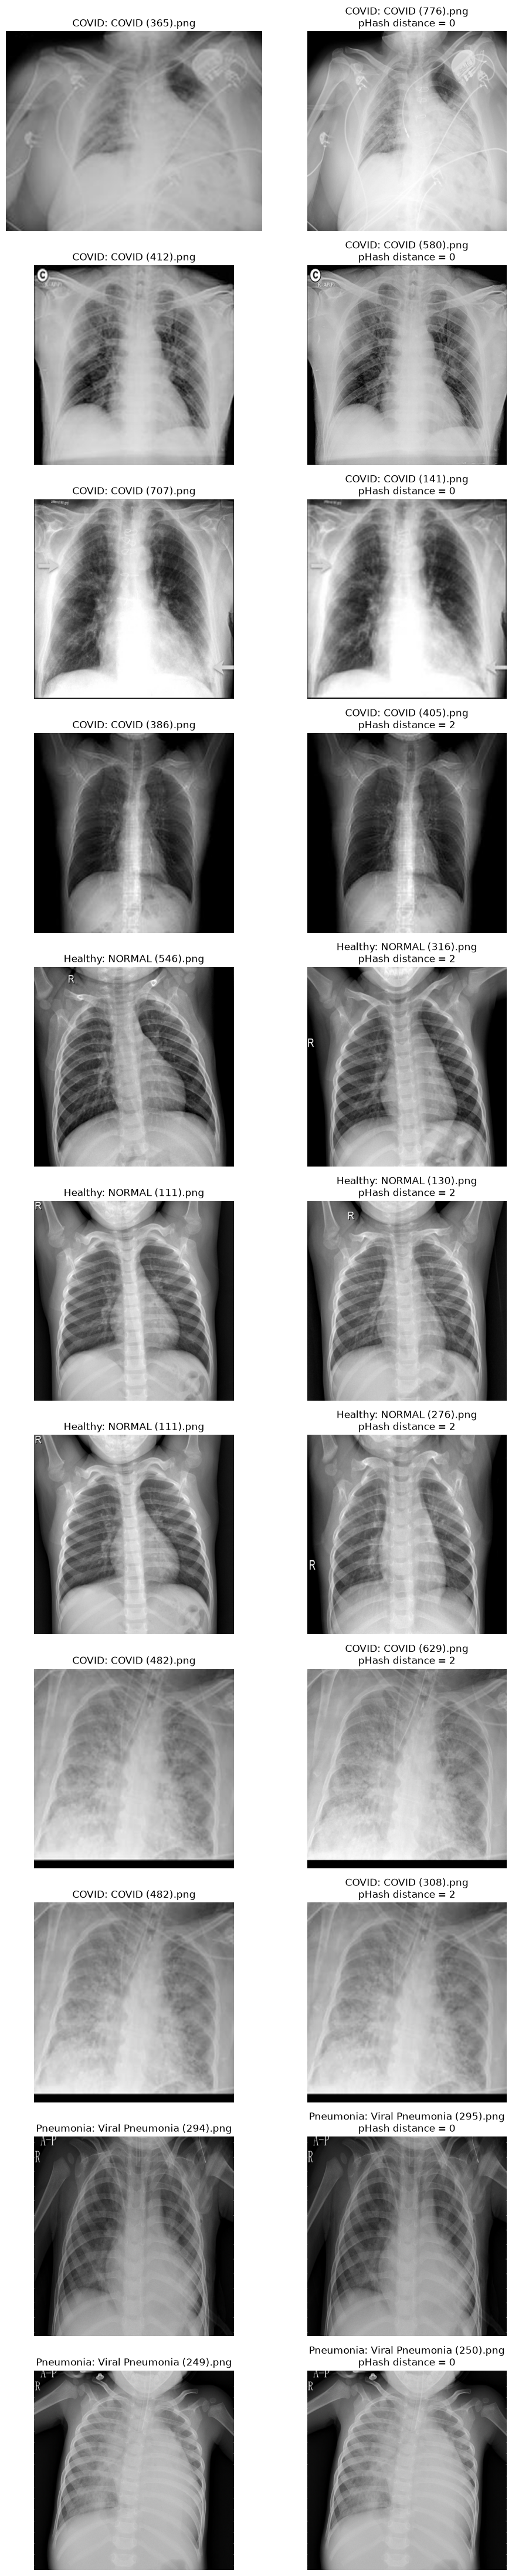

In [13]:
# Select up to 3 examples from each class/distance combination
review_pairs = (
    near_duplicate_df
    .groupby(["label_1", "label_2", "phash_distance"], group_keys=False)
    .head(3)
    .head(12)
    .reset_index(drop=True)
)

fig, axes = plt.subplots(len(review_pairs), 2, figsize=(10, 4 * len(review_pairs)))

for row_idx, pair in review_pairs.iterrows():
    image1 = dataset1_clean_df.iloc[pair["index_1"]]
    image2 = dataset1_clean_df.iloc[pair["index_2"]]

    with Image.open(image1["filepath"]) as img:
        axes[row_idx, 0].imshow(img, cmap="gray")

    with Image.open(image2["filepath"]) as img:
        axes[row_idx, 1].imshow(img, cmap="gray")

    axes[row_idx, 0].set_title(
        f'{image1["label"]}: {image1["filename"]}'
    )
    axes[row_idx, 1].set_title(
        f'{image2["label"]}: {image2["filename"]}\n'
        f'pHash distance = {pair["phash_distance"]}'
    )

    axes[row_idx, 0].axis("off")
    axes[row_idx, 1].axis("off")

plt.tight_layout()
plt.show()

In [14]:
dataset1_manifest = dataset1_clean_df[
    [
        "filepath",
        "filename",
        "label",
        "source_dataset",
        "exact_hash",
        "phash"
    ]
].copy()

print("Dataset 1 manifest shape:", dataset1_manifest.shape)
display(dataset1_manifest.head())

Dataset 1 manifest shape: (3880, 6)


,filepath,filename,label,source_dataset,exact_hash,phash
0,C:\Users\rosen\Documents\AIS\EDA_PSUPR_Project...,COVID (365).png,COVID,COVID_Radiography_Database,001e909ea5d22da6853adb6c07ca43b471ec928a6375ec...,813d0c1c1b1f5f79
1,C:\Users\rosen\Documents\AIS\EDA_PSUPR_Project...,Viral Pneumonia (488).png,Pneumonia,COVID_Radiography_Database,002b48dc099c3185e06ad9d7acfa79c0ed66c7cda8a420...,812ae63eda5f1643
2,C:\Users\rosen\Documents\AIS\EDA_PSUPR_Project...,NORMAL (778).png,Healthy,COVID_Radiography_Database,002d3844c2d1d63780ec54afb4c40c243654f513dfebcf...,9d7d831a0b3c6c6c
3,C:\Users\rosen\Documents\AIS\EDA_PSUPR_Project...,NORMAL (157).png,Healthy,COVID_Radiography_Database,0055d690b529a000198d429a9f202814a15df8201c5957...,956e8f2f0d4c6cc4
4,C:\Users\rosen\Documents\AIS\EDA_PSUPR_Project...,NORMAL (995).png,Healthy,COVID_Radiography_Database,005d4a56537746139553c4a2e23a62bb613f8eb8956b12...,9839c65ada591979


Preserve original classes and create the binary targets

In [15]:
dataset1_manifest = dataset1_clean_df.copy()

# Preserve the clinical/original class:
# COVID, Healthy, or Pneumonia
dataset1_manifest["original_label"] = dataset1_manifest["label"]

# Binary target for COVID vs non-COVID experiments
dataset1_manifest["covid_target"] = (
    dataset1_manifest["original_label"] == "COVID"
).astype(int)

print("Original class distribution:")
print(dataset1_manifest["original_label"].value_counts())

print("\nBinary target distribution:")
print(dataset1_manifest["covid_target"].value_counts().sort_index())

display(
    dataset1_manifest[
        [
            "filename",
            "original_label",
            "covid_target",
            "source_dataset",
            "exact_hash",
            "phash"
        ]
    ].head()
)

Original class distribution:
original_label
Pneumonia    1340
Healthy      1340
COVID        1200
Name: count, dtype: int64

Binary target distribution:
covid_target
0    2680
1    1200
Name: count, dtype: int64


,filename,original_label,covid_target,source_dataset,exact_hash,phash
0,COVID (365).png,COVID,1,COVID_Radiography_Database,001e909ea5d22da6853adb6c07ca43b471ec928a6375ec...,813d0c1c1b1f5f79
1,Viral Pneumonia (488).png,Pneumonia,0,COVID_Radiography_Database,002b48dc099c3185e06ad9d7acfa79c0ed66c7cda8a420...,812ae63eda5f1643
2,NORMAL (778).png,Healthy,0,COVID_Radiography_Database,002d3844c2d1d63780ec54afb4c40c243654f513dfebcf...,9d7d831a0b3c6c6c
3,NORMAL (157).png,Healthy,0,COVID_Radiography_Database,0055d690b529a000198d429a9f202814a15df8201c5957...,956e8f2f0d4c6cc4
4,NORMAL (995).png,Healthy,0,COVID_Radiography_Database,005d4a56537746139553c4a2e23a62bb613f8eb8956b12...,9839c65ada591979


In [16]:
#add image properties measured during EDA for future ready 3 class target.

# Add the properties measured during EDA
dataset1_manifest = dataset1_manifest.merge(
    properties_df[
        ["filepath", "mode", "width", "height", "aspect_ratio"]
    ],
    on="filepath",
    how="left",
    validate="one_to_one"
)

# Future three-class target
multiclass_label_to_id = {
    "Healthy": 0,
    "Pneumonia": 1,
    "COVID": 2
}

dataset1_manifest["multiclass_target"] = (
    dataset1_manifest["original_label"]
    .map(multiclass_label_to_id)
)

# Safety checks
assert len(dataset1_manifest) == 3880
assert dataset1_manifest["filepath"].isna().sum() == 0
assert dataset1_manifest["exact_hash"].duplicated().sum() == 0
assert dataset1_manifest["multiclass_target"].isna().sum() == 0

print("Dataset 1 manifest shape:", dataset1_manifest.shape)

print("\nThree-class mapping:")
print(
    dataset1_manifest[
        ["original_label", "multiclass_target"]
    ]
    .drop_duplicates()
    .sort_values("multiclass_target")
)

display(dataset1_manifest.head())

Dataset 1 manifest shape: (3880, 13)

Three-class mapping:
  original_label  multiclass_target
2        Healthy                  0
1      Pneumonia                  1
0          COVID                  2


,filepath,filename,label,source_dataset,exact_hash,phash,original_label,covid_target,mode,width,height,aspect_ratio,multiclass_target
0,C:\Users\rosen\Documents\AIS\EDA_PSUPR_Project...,COVID (365).png,COVID,COVID_Radiography_Database,001e909ea5d22da6853adb6c07ca43b471ec928a6375ec...,813d0c1c1b1f5f79,COVID,1,RGB,253,197,1.2843,2
1,C:\Users\rosen\Documents\AIS\EDA_PSUPR_Project...,Viral Pneumonia (488).png,Pneumonia,COVID_Radiography_Database,002b48dc099c3185e06ad9d7acfa79c0ed66c7cda8a420...,812ae63eda5f1643,Pneumonia,0,L,1024,1024,1.0000,1
2,C:\Users\rosen\Documents\AIS\EDA_PSUPR_Project...,NORMAL (778).png,Healthy,COVID_Radiography_Database,002d3844c2d1d63780ec54afb4c40c243654f513dfebcf...,9d7d831a0b3c6c6c,Healthy,0,L,1024,1024,1.0000,0
3,C:\Users\rosen\Documents\AIS\EDA_PSUPR_Project...,NORMAL (157).png,Healthy,COVID_Radiography_Database,0055d690b529a000198d429a9f202814a15df8201c5957...,956e8f2f0d4c6cc4,Healthy,0,L,1024,1024,1.0000,0
4,C:\Users\rosen\Documents\AIS\EDA_PSUPR_Project...,NORMAL (995).png,Healthy,COVID_Radiography_Database,005d4a56537746139553c4a2e23a62bb613f8eb8956b12...,9839c65ada591979,Healthy,0,L,1024,1024,1.0000,0


PREPROCESSING STEP 1: RGB CONVERSION AND RESIZE WITH PADDING

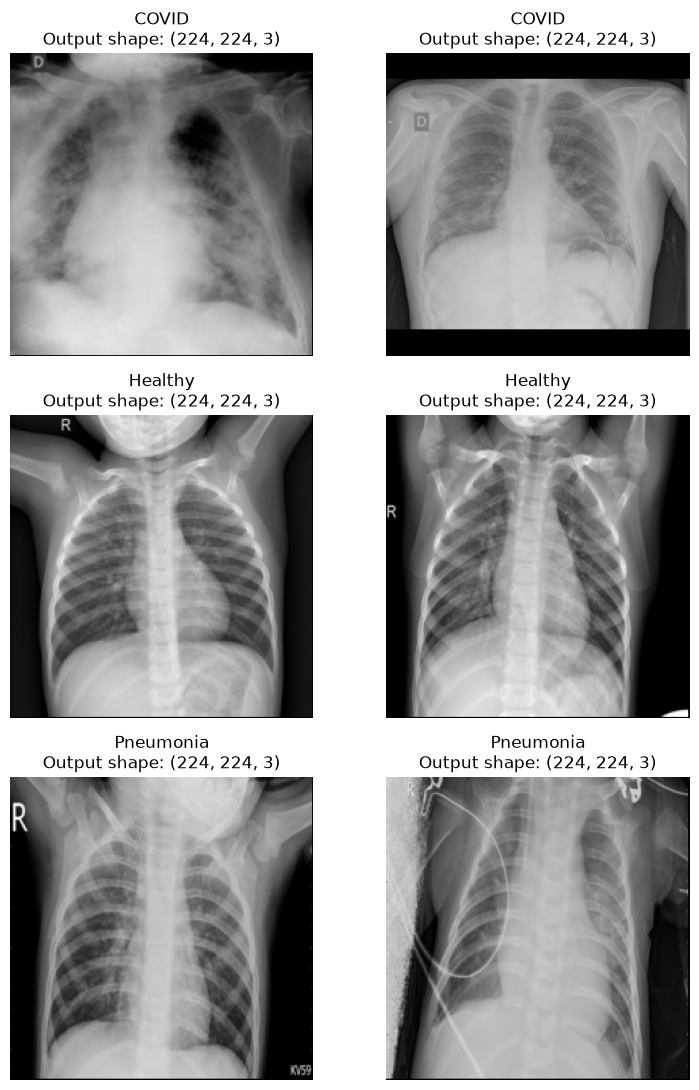

Standardised output shape: (224, 224, 3)
Pixel range: 0.0 to 208.65895080566406


In [17]:
import tensorflow as tf
import matplotlib.pyplot as plt

IMG_SIZE = (224, 224)

def load_base_image(filepath):
    # Works for both PNG (Dataset 1) and JPEG (Dataset 2)
    image_bytes = tf.io.read_file(filepath)

    # Forces all grayscale/RGB images into 3 RGB channels
    image = tf.io.decode_image(
        image_bytes,
        channels=3,
        expand_animations=False
    )
    image.set_shape([None, None, 3])

    # Keep the raw 0-255 pixel scale for now
    image = tf.cast(image, tf.float32)

    # Preserves aspect ratio; adds black padding where required
    image = tf.image.resize_with_pad(
        image,
        target_height=IMG_SIZE[0],
        target_width=IMG_SIZE[1],
        antialias=True
    )

    return image

# Validate one sample from each Dataset 1 class
samples = (
    dataset1_manifest
    .groupby("original_label", group_keys=False)
    .sample(n=2, random_state=42)
    .reset_index(drop=True)
)

fig, axes = plt.subplots(3, 2, figsize=(8, 11))

for ax, (_, row) in zip(axes.ravel(), samples.iterrows()):
    image = load_base_image(row["filepath"]).numpy().astype("uint8")

    ax.imshow(image)
    ax.set_title(
        f'{row["original_label"]}\n'
        f'Output shape: {image.shape}'
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

# Technical check
test_image = load_base_image(dataset1_manifest.iloc[0]["filepath"])

print("Standardised output shape:", test_image.shape)
print(
    "Pixel range:",
    float(tf.reduce_min(test_image)),
    "to",
    float(tf.reduce_max(test_image))
)

FOR THIS DATASET PREPROCESSING, WE WILL ONLY DO RGB CONVERSION AND IMG RESIZING. THE REST OF THE PREPROCESSING STEPS WILL BE DONE AFTER COMBING WITH DATASET2
model-specific normalisation;
augmentation, because it must be training-only;
splitting;
class weights.

In [18]:
# SAVE THE CLEAN DATASET
from pathlib import Path

manifest_dir = Path(base_path).parent / "manifests"
manifest_dir.mkdir(exist_ok=True)

dataset1_manifest_path = manifest_dir / "dataset1_clean_manifest.csv"

dataset1_manifest.to_csv(
    dataset1_manifest_path,
    index=False
)

print(f"Saved Dataset 1 manifest to:\n{dataset1_manifest_path}")
print(f"\nRows saved: {len(dataset1_manifest)}")

Saved Dataset 1 manifest to:
C:\Users\rosen\Documents\AIS\EDA_PSUPR_Project\manifests\dataset1_clean_manifest.csv

Rows saved: 3880
